In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

from collections import Counter

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,accuracy_score,roc_curve,classification_report,f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
# from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import lightgbm as lgb
# from mlxtend.classifier import StackingCVClassifier
import warnings
warnings.filterwarnings('ignore')


In [2]:
data = pd.read_csv('Churn.csv')
X = data.drop(['Exited'],axis = 1)
y = data['Exited']

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(X, y ,test_size= 0.3, random_state= 42)

In [3]:
model = lgb.LGBMClassifier(verbose=-1)

model.fit(x_train, y_train)

lgb_pred = model.predict(x_test)

In [4]:
accuracy_score(y_test, lgb_pred)

0.8531639433661207

In [5]:
import shap

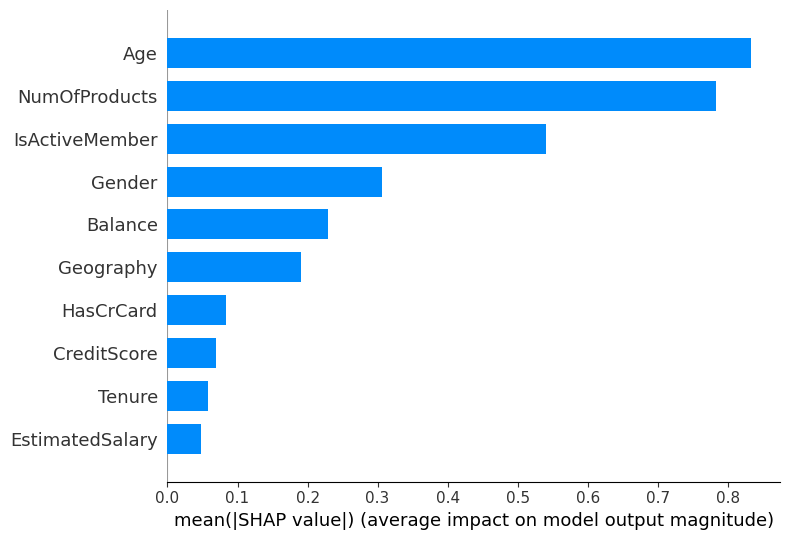

In [6]:
import time
s = time.time()

explainer = shap.Explainer(model)
shap_values = explainer.shap_values(x_test)

# Visualize SHAP values
shap.summary_plot(shap_values, x_test, plot_type="bar")

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming you have already calculated shap_values

# Generate the summary plot with bar chart
shap.summary_plot(shap_values, x_test, plot_type="bar", show=False, color='c')

# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(shap_values, columns=x_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)

In [8]:
shap_values_per_feature_sorted

EstimatedSalary    0.048417
Tenure             0.057795
CreditScore        0.069511
HasCrCard          0.083545
Geography          0.190220
Balance            0.229651
Gender             0.305541
IsActiveMember     0.540072
NumOfProducts      0.782540
Age                0.832777
dtype: float64

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Assuming you have already calculated shap_values and x_test

# Generate the summary plot with bar chart
# shap.summary_plot(shap_values, x_test, plot_type="bar", show=False, color='c')

# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(shap_values, columns=x_test.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)

# 最小-最大归一化到 [0, 1] 之间
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=True)
shap_values_per_feature_normalized

EstimatedSalary    0.000000
Tenure             0.011956
CreditScore        0.026893
HasCrCard          0.044785
Geography          0.180787
Balance            0.231059
Gender             0.327814
IsActiveMember     0.626824
NumOfProducts      0.935952
Age                1.000000
dtype: float64

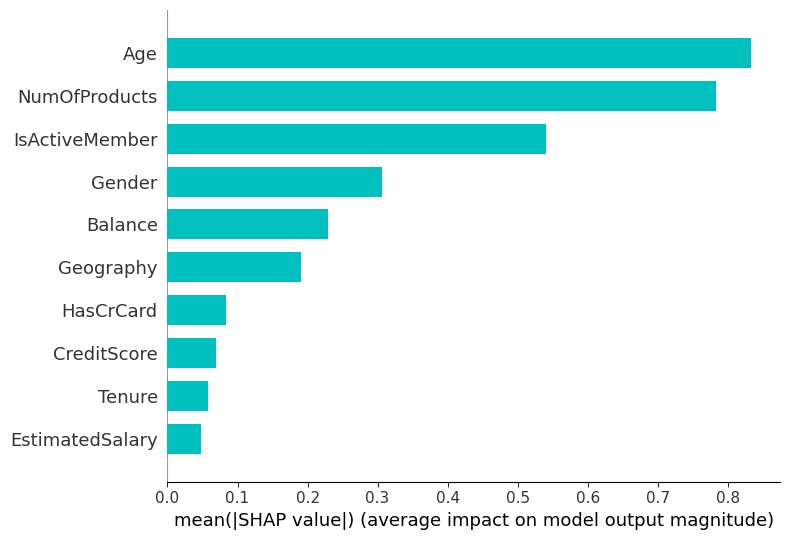

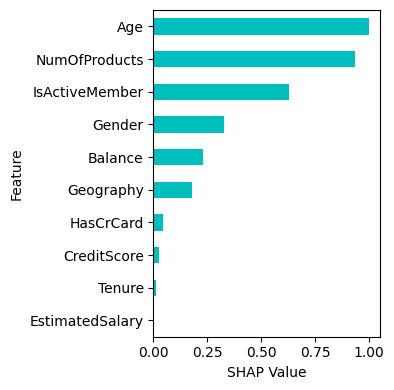

In [10]:
# Create a vertical figure for better spacing
plt.figure(figsize=(4, 4))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized.plot(kind='barh', color='c')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

# plt.savefig('shap_bank_lgb_normalized.eps', format='eps', dpi=300)

plt.show()

In [11]:
e = time.time()
e-s

1.0917768478393555

In [12]:
import time
s = time.time()

# Get feature importances
feature_importance = model.feature_importances_

# Create a DataFrame to display feature names and their corresponding importance values
feature_importance_df = pd.DataFrame({'Feature': x_train.columns, 'Importance': feature_importance})

# Sort the features based on their importance values
sorted_feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Display the sorted feature importances
print(sorted_feature_importance_df)


           Feature  Importance
5          Balance         559
0      CreditScore         515
9  EstimatedSalary         474
3              Age         386
1        Geography         270
4           Tenure         210
8   IsActiveMember         183
2           Gender         170
6    NumOfProducts         158
7        HasCrCard          75


In [13]:
# 最小-最大归一化到 [0, 1] 之间
sorted_feature_importance_df['Normalized Importance'] = (
    sorted_feature_importance_df['Importance'] - sorted_feature_importance_df['Importance'].min()
) / (
    sorted_feature_importance_df['Importance'].max() - sorted_feature_importance_df['Importance'].min()
)

# 打印归一化后的特征重要性
sorted_feature_importance_df

,Feature,Importance,Normalized Importance
5,Balance,559,1.000000
0,CreditScore,515,0.909091
9,EstimatedSalary,474,0.824380
3,Age,386,0.642562
1,Geography,270,0.402893
4,Tenure,210,0.278926
8,IsActiveMember,183,0.223140
2,Gender,170,0.196281
6,NumOfProducts,158,0.171488
7,HasCrCard,75,0.000000


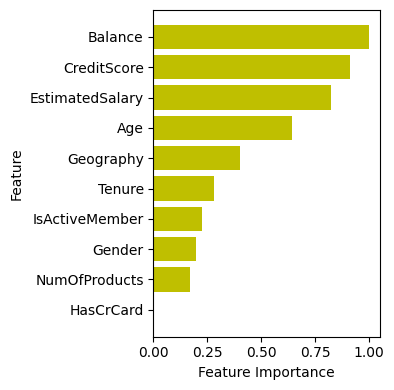

In [14]:
plt.figure(figsize=(4, 4))  # 改变图形大小，使其适应竖向显示
plt.barh(sorted_feature_importance_df['Feature'], sorted_feature_importance_df['Normalized Importance'], color='y')
plt.ylabel('Feature')
plt.xlabel('Feature Importance')
# plt.title('Feature Importance')
plt.gca().invert_yaxis()  # 反转y轴，使重要性最高的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
# plt.savefig('feature_importance_bank_lgb_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()

In [15]:
e = time.time()
e-s

0.044457197189331055

In [16]:
import time
s = time.time()

from lime import lime_tabular
explainer = lime_tabular.LimeTabularExplainer(x_train.values, mode="classification", feature_names=x_train.columns)
sample_idx = 0  # Choose an index of the test set
exp = explainer.explain_instance(x_test.iloc[sample_idx].values, model.predict_proba, num_features=len(x_train.columns))
# exp.show_in_notebook()

In [17]:
# Extract feature values and their weights
feature_values = exp.as_list()

# Sort the features based on their weights
sorted_features = sorted(feature_values, key=lambda x: x[1], reverse=True)

# Print the sorted features and their weights
for feature in sorted_features:
    print(f"Feature: {feature[0]}, Weight: {feature[1]}")

Feature: NumOfProducts <= 1.00, Weight: 0.16532737890739438
Feature: IsActiveMember <= 0.00, Weight: 0.1451764835689093
Feature: Gender <= 0.00, Weight: 0.07498235599805246
Feature: CreditScore > 710.00, Weight: 0.003492794295420426
Feature: HasCrCard <= 1.00, Weight: 0.0
Feature: Tenure > 7.00, Weight: -0.004067594954846979
Feature: 74836.34 < EstimatedSalary <= 118024.60, Weight: -0.007104179568542131
Feature: 0.00 < Balance <= 120145.43, Weight: -0.019160816075312948
Feature: Geography <= 0.00, Weight: -0.03390068423310611
Feature: Age <= 32.00, Weight: -0.15284339487480675


In [18]:
# 提取特征值及其权重
feature_values = exp.as_map()[1]

# 根据权重的绝对值对特征进行排序
sorted_features = sorted(feature_values, key=lambda x: abs(x[1]), reverse=True)

# 提取特征名称和权重
features = [x_test.columns[i] for i, _ in sorted_features]
weights = [weight for _, weight in sorted_features]

# 打印排序后的特征及其权重（按绝对值排序）
# print("Sorted features by absolute weight (from largest to smallest):")
for feature, weight in zip(features, weights):
    print(f"Feature: {feature}, Weight: {abs(weight)}")


Feature: NumOfProducts, Weight: 0.16532737890739438
Feature: Age, Weight: 0.15284339487480675
Feature: IsActiveMember, Weight: 0.1451764835689093
Feature: Gender, Weight: 0.07498235599805246
Feature: Geography, Weight: 0.03390068423310611
Feature: Balance, Weight: 0.019160816075312948
Feature: EstimatedSalary, Weight: 0.007104179568542131
Feature: Tenure, Weight: 0.004067594954846979
Feature: CreditScore, Weight: 0.003492794295420426
Feature: HasCrCard, Weight: 0.0


In [19]:
abs_weights = [abs(weight) for weight in weights]
# 归一化处理
min_abs_weight = min(abs_weights)
max_abs_weight = max(abs_weights)
normalized_weights = [(w - min_abs_weight) / (max_abs_weight - min_abs_weight) for w in abs_weights]
normalized_weights

[1.0,
 0.9244893125682447,
 0.8781151950048619,
 0.4535386485504781,
 0.2050518459625194,
 0.11589620667757387,
 0.04297037559956376,
 0.024603274918701644,
 0.021126532813278687,
 0.0]

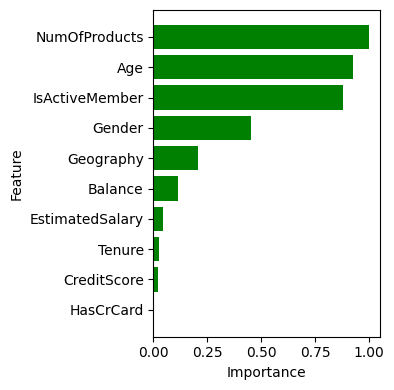

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# 计算绝对权重
abs_weights = [abs(weight) for weight in weights]

# 归一化处理
min_abs_weight = min(abs_weights)
max_abs_weight = max(abs_weights)
normalized_weights = [(w - min_abs_weight) / (max_abs_weight - min_abs_weight) for w in abs_weights]

# 绘制归一化后的特征权重条形图
plt.figure(figsize=(4, 4))
plt.barh(features, normalized_weights, color='g')  # 使用归一化后的权重
plt.xlabel('Importance')  # 修改x轴标签
plt.ylabel('Feature')
# plt.title('LIME Feature Weights (Normalized Absolute Values)')  # 修改标题
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
# plt.savefig('lime_bank_lgb_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()

In [21]:
e = time.time()
e-s

0.25426816940307617

In [22]:
import time
s = time.time()

from sklearn.inspection import permutation_importance
import numpy as np
result = permutation_importance(model, x_test, y_test, n_repeats=1, random_state=42, scoring='neg_mean_squared_error')

# 打印特征重要性
feature_names = X.columns.tolist()
importances = result.importances_mean
std = result.importances_std
indices = np.argsort(importances)[::-1]

print("Feature ranking:")
for f in range(x_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({importances[indices[f]]:.6f})")

Feature ranking:
1. feature Age (0.073176)
2. feature NumOfProducts (0.041122)
3. feature IsActiveMember (0.025570)
4. feature Balance (0.014037)
5. feature Geography (0.013169)
6. feature Gender (0.006584)
7. feature CreditScore (0.000707)
8. feature HasCrCard (0.000222)
9. feature EstimatedSalary (0.000020)
10. feature Tenure (-0.000061)


In [23]:
# 归一化处理
min_importance = np.min(importances)
max_importance = np.max(importances)
normalized_importances = (importances - min_importance) / (max_importance - min_importance)

# 按归一化后的重要性排序
indices = np.argsort(normalized_importances)[::-1]

# 打印归一化后的特征重要性
print("Feature ranking (normalized importance):")
for f in range(x_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({normalized_importances[indices[f]]:.6f})")

Feature ranking (normalized importance):
1. feature Age (1.000000)
2. feature NumOfProducts (0.562328)
3. feature IsActiveMember (0.349972)
4. feature Balance (0.192499)
5. feature Geography (0.180640)
6. feature Gender (0.090734)
7. feature CreditScore (0.010480)
8. feature HasCrCard (0.003861)
9. feature EstimatedSalary (0.001103)
10. feature Tenure (0.000000)


In [24]:
# 创建一个数据框来存储特征及其重要性
feature_importance_df = pd.DataFrame({
    'Feature': [feature_names[i] for i in indices],
    'Importance': normalized_importances[indices],
    'Std': std[indices]
})

# 按重要性排序
sorted_feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=True)

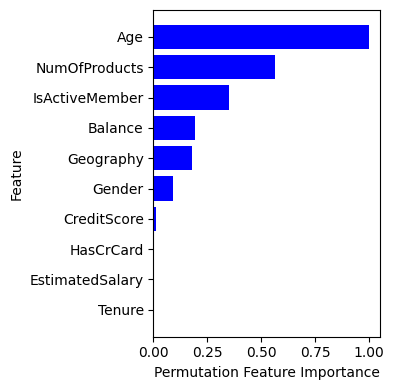

In [25]:
# 画图
plt.figure(figsize=(4, 4))  # 改变图形大小，使其适应竖向显示
plt.barh(sorted_feature_importance_df['Feature'], sorted_feature_importance_df['Importance'], color='b')
plt.ylabel('Feature')
plt.xlabel('Permutation Feature Importance')
# plt.gca().invert_yaxis()  # 反转y轴，使重要性最高的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
# plt.savefig('Permutation_importance_bank_lgb_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()

In [26]:
e = time.time()
e-s

0.38964295387268066